# Steady lid-driven cavity: P1/P1 with SUPG and PSPG

This notebook uses **FEniCSx (`dolfinx`)** and is designed to run cell by cell in Google Colab. It solves the nondimensional, steady, incompressible Navier–Stokes equations on the unit square $\Omega=(0,1)^2$:

$$
(\mathbf u\cdot\nabla)\mathbf u-\nabla\cdot(2\nu\boldsymbol\varepsilon(\mathbf u))+\nabla p=\mathbf0,
\qquad \nabla\cdot\mathbf u=0,
\qquad \boldsymbol\varepsilon(\mathbf u)=\tfrac12(\nabla\mathbf u+\nabla\mathbf u^T).
$$

The cavity width and lid speed are both 1, so $\nu=1/\mathrm{Re}$. Velocity and pressure both use continuous **P1 elements**. The interior nodes of the lid have velocity $(1,0)$; the left, right, and bottom walls have velocity $(0,0)$. The two upper corners belong to the stationary side walls so that no node receives conflicting velocity values. Velocity is imposed strongly through Dirichlet degrees of freedom. Pressure is set to zero at the lower-left corner solely to fix its otherwise arbitrary additive constant.

The supplied parameters perform a **direct steady solve at $\mathrm{Re}=400$**. A commented Reynolds-number sequence shows how to enable continuation if desired. No time derivative or time stepping is used.


## 1. Install FEniCSx in Google Colab

The first run uses the [FEM on Colab](https://fem-on-colab.github.io/packages.html) release script to install the real-scalar build. Run this cell again after resetting the Colab runtime. Python's `subprocess` runs the same `wget` and `bash` commands as the shell installation example.


In [1]:
# Reuse an existing installation when the Colab runtime already has FEniCSx.
try:
    import dolfinx
except ImportError:
    # Install the real-scalar release into this Colab runtime.
    import subprocess
    install_url = "https://fem-on-colab.github.io/releases/fenicsx-install-release-real.sh"
    install_script = "/tmp/fenicsx-install.sh"
    subprocess.run(["wget", install_url, "-O", install_script], check=True)
    subprocess.run(["bash", install_script], check=True)
    import dolfinx

print("dolfinx version:", dolfinx.__version__)


dolfinx version: 0.11.0


## 2. Parameters and mixed finite element space

`N` is the number of divisions along each side of the triangular mesh. `TARGET_RE` is the requested Reynolds number. The current `RE_STEPS` list contains only `TARGET_RE`, giving a direct solve from a zero initial field. To use continuation, select the commented, increasing sequence instead. `basix.ufl.mixed_element` combines vector-valued P1 velocity with scalar-valued P1 pressure in one mixed space.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import ufl
from basix.ufl import element, mixed_element
from mpi4py import MPI
from petsc4py import PETSc
from dolfinx import fem, mesh as dmesh
from dolfinx.fem.petsc import NonlinearProblem

# Numerical settings: N = 100 gives 100 divisions along each cavity side.
N = 100
TARGET_RE = 400.0
# Uncomment the next line for Reynolds-number continuation if needed.
RE_STEPS = [1.0, 10.0, 50.0, 100, 200, TARGET_RE]
# RE_STEPS = [TARGET_RE]  # you can also solve this directly

# Ensure that the solve sequence ends at the requested Reynolds number.
assert RE_STEPS[-1] == TARGET_RE
assert all(b > a for a, b in zip(RE_STEPS, RE_STEPS[1:]))

# Build the triangular unit-square mesh and equal-order P1/P1 space.
msh = dmesh.create_unit_square(MPI.COMM_WORLD, N, N, cell_type=dmesh.CellType.triangle)
cell = msh.basix_cell()
velocity_p1 = element("Lagrange", cell, 1, shape=(2,))
pressure_p1 = element("Lagrange", cell, 1)
W = fem.functionspace(msh, mixed_element([velocity_p1, pressure_p1]))

# The mixed Function holds velocity and pressure throughout the nonlinear solve.
solution = fem.Function(W)
solution.name = "velocity_pressure"
u, p = ufl.split(solution)
v, q = ufl.TestFunctions(W)
# Kinematic viscosity is updated to 1/Re before every steady solve.
nu = fem.Constant(msh, PETSc.ScalarType(1.0))


## 3. Strongly imposed boundary conditions

FEniCSx locates degrees of freedom with `locate_dofs_topological` or `locate_dofs_geometrical`, then applies `dirichletbc`. The moving-lid selector excludes the upper corners, which are assigned zero velocity by the side-wall condition. One lower-left pressure degree of freedom is set to zero as a reference; pressure elsewhere remains an unknown.


In [11]:
# Collapse the mixed subspaces to create compatible boundary-value Functions.
velocity_sub = W.sub(0)
pressure_sub = W.sub(1)
V, _ = velocity_sub.collapse()
Q, _ = pressure_sub.collapse()

# FEniCSx initializes these zero boundary-value Functions to zero.
zero_velocity = fem.Function(V)
lid_velocity = fem.Function(V)
lid_velocity.interpolate(lambda x: np.vstack((np.ones(x.shape[1]), np.zeros(x.shape[1]))))
zero_pressure = fem.Function(Q)

# The top corners are assigned to the stationary side walls.
def walls(x):
    return np.isclose(x[0], 0.0) | np.isclose(x[0], 1.0) | np.isclose(x[1], 0.0)

# Exclude x = 0 and x = 1 to avoid conflicting values at corners.
def lid_interior(x):
    return np.isclose(x[1], 1.0) & (x[0] > 1.0e-10) & (x[0] < 1.0 - 1.0e-10)

# Fix just one pressure DOF to eliminate the constant-pressure nullspace.
def pressure_corner(x):
    return np.isclose(x[0], 0.0) & np.isclose(x[1], 0.0)

# Map selected facets/nodes from collapsed spaces into the mixed space.
facets = dmesh.locate_entities_boundary(msh, msh.topology.dim - 1, walls)
wall_dofs = fem.locate_dofs_topological((velocity_sub, V), msh.topology.dim - 1, facets)
lid_dofs = fem.locate_dofs_geometrical((velocity_sub, V), lid_interior)
pressure_dofs = fem.locate_dofs_geometrical((pressure_sub, Q), pressure_corner)

bcs = [
    fem.dirichletbc(zero_velocity, wall_dofs, velocity_sub),
    fem.dirichletbc(lid_velocity, lid_dofs, velocity_sub),
    fem.dirichletbc(zero_pressure, pressure_dofs, pressure_sub),
]
print(f"Wall: {len(wall_dofs)}, lid: {len(lid_dofs)}, pressure pin: {len(pressure_dofs)} DOFs")


Wall: 2, lid: 2, pressure pin: 2 DOFs


## 4. Galerkin, SUPG, and PSPG formulation

The elementwise strong momentum residual is

$$\mathbf R_M=(\mathbf u\cdot\nabla)\mathbf u+\nabla p
-\nabla\cdot\bigl(2\nu\boldsymbol\varepsilon(\mathbf u)\bigr).$$

In addition to the standard Galerkin form, we add

$$\sum_K\int_K\tau_K(\mathbf u\cdot\nabla\mathbf v)\cdot\mathbf R_M\,\mathrm d\Omega
\quad\text{(SUPG)},\qquad
\sum_K\int_K\tau_K\nabla q\cdot\mathbf R_M\,\mathrm d\Omega
\quad\text{(PSPG)}.$$

Following Franca and Frey for P1 triangles, use $m_1=1/3$, $\lambda=1$, and

$$\mathrm{Re}_K=\frac{m_1|\mathbf u|h_K}{4\nu},\qquad
\xi_K=\min(\mathrm{Re}_K,1),$$

$$\tau_K=\frac{h_K}{2|\mathbf u|}\xi_K
=\min\!\left(\frac{h_K}{2|\mathbf u|},\frac{h_K^2}{24\nu}\right),\qquad
\delta_K=\lambda|\mathbf u|h_K\xi_K.$$

Here $h_K$ is the cell diameter. A small regularization of $|\mathbf u|$ prevents division by zero in the code. Add the divergence stabilization term

$$\sum_K\int_K\delta_K(\nabla\cdot\mathbf u)(\nabla\cdot\mathbf v)\,\mathrm d\Omega.$$

SUPG acts along the convective direction, and PSPG stabilizes the equal-order P1/P1 pressure approximation. On affine P1 triangles, the velocity gradient is constant within each cell, so the viscous second-derivative contribution to the strong residual vanishes in each cell interior. The full residual is retained in the code to state the formulation explicitly.


In [12]:
# Cell diameter and a fixed quadrature order for the nonlinear integrands.
h = ufl.CellDiameter(msh)
dxq = ufl.Measure("dx", domain=msh, metadata={"quadrature_degree": 5})
strain_u = ufl.sym(ufl.grad(u))

# Elementwise strong momentum residual; P1 viscous second derivatives
# vanish within each affine triangle, but the complete expression is retained.
R_m = ufl.dot(ufl.grad(u), u) + ufl.grad(p) - ufl.div(2.0 * nu * strain_u)
# Franca-Frey parameters for equal-order P1 triangles. The small offset
# regularizes the speed at stagnation points in the tau expression.
speed = ufl.sqrt(ufl.dot(u, u) + 1.0e-12)
m_1 = 1.0 / 3.0
lambda_div = 1.0
Re_K = m_1 * speed * h / (4.0 * nu)
xi_K = ufl.min_value(Re_K, 1.0)
tau = h * xi_K / (2.0 * speed)
delta = lambda_div * speed * h * xi_K

# Weak convection, viscous stress, pressure, and continuity terms.
F_galerkin = (
    ufl.inner(ufl.dot(ufl.grad(u), u), v)
    + 2.0 * nu * ufl.inner(strain_u, ufl.sym(ufl.grad(v)))
    - p * ufl.div(v)
    + q * ufl.div(u)
) * dxq

# SUPG weights the momentum residual by the streamline test direction.
F_supg = tau * ufl.inner(ufl.dot(ufl.grad(v), u), R_m) * dxq
# PSPG weights the same residual by the pressure-test gradient.
F_pspg = tau * ufl.inner(ufl.grad(q), R_m) * dxq
# Divergence stabilization penalizes the elementwise velocity divergence.
# F_div = delta * ufl.div(u) * ufl.div(v) * dxq   ##** the divergence term can be removed/added
F = F_galerkin + F_supg + F_pspg # + F_div


## 5. PETSc SNES solver and nonlinear iteration progress

The nonlinear problem uses Newton's method with a backtracking line search. `setMonitor` prints the residual norm at every nonlinear iteration, together with its ratio to the initial residual for that Reynolds-number solve. The solver reports the iteration count and convergence reason after each solve, and raises an error if it fails. With the current one-item `RE_STEPS` list, there is only one solve at `Re = 400`; with continuation enabled, each converged solution initializes the next Reynolds number.


In [13]:
# Newton with backtracking and a direct linear solver for each step.
petsc_options = {
    "snes_type": "newtonls",
    "snes_linesearch_type": "bt",
    "snes_atol": 1.0e-10,
    "snes_rtol": 1.0e-8,
    "snes_max_it": 40,
    "ksp_type": "preonly",
    "pc_type": "lu",  # PETSc selects an available LU factorization.
}

problem = NonlinearProblem(
    F,
    solution,
    bcs=bcs,
    petsc_options_prefix="steady_cavity_supg_pspg_",
    petsc_options=petsc_options,
)

# Store each SNES residual sequence for the convergence plot.
histories = {}
active_re = None

def nonlinear_monitor(snes, iteration, residual_norm):
    """Record and display the nonlinear residual after each SNES iteration."""
    histories[active_re].append(float(residual_norm))
    initial_norm = histories[active_re][0]
    ratio = residual_norm / initial_norm if initial_norm > 0.0 else 0.0
    if msh.comm.rank == 0:
        print(f"  Newton {iteration:2d}: |F| = {residual_norm:.6e}, |F|/|F0| = {ratio:.6e}", flush=True)

problem.solver.setMonitor(nonlinear_monitor)

# With one entry this solves directly; multiple entries enable continuation.
for active_re in RE_STEPS:
    nu.value = PETSc.ScalarType(1.0 / active_re)
    histories[active_re] = []
    if msh.comm.rank == 0:
        print(f"\n=== Steady solve: Re = {active_re:g} ===", flush=True)

    problem.solve()  # Reuses the preceding solution when a prior stage exists.
    reason = problem.solver.getConvergedReason()
    steps = problem.solver.getIterationNumber()
    if msh.comm.rank == 0:
        print(f"Result: iterations = {steps}, converged reason = {reason}", flush=True)
    # PETSc uses positive convergence reasons and nonpositive failure reasons.
    if reason <= 0:
        raise RuntimeError(f"Nonlinear solve did not converge at Re = {active_re:g} (reason {reason}).")

solution.x.scatter_forward()



=== Steady solve: Re = 1 ===
  Newton  0: |F| = 1.408013e+01, |F|/|F0| = 1.000000e+00
  Newton  1: |F| = 5.845286e-03, |F|/|F0| = 4.151444e-04
  Newton  2: |F| = 8.437409e-08, |F|/|F0| = 5.992423e-09
Result: iterations = 2, converged reason = 3

=== Steady solve: Re = 10 ===
  Newton  0: |F| = 2.175099e+00, |F|/|F0| = 1.000000e+00
  Newton  1: |F| = 3.859164e-05, |F|/|F0| = 1.774248e-05
  Newton  2: |F| = 1.090311e-11, |F|/|F0| = 5.012696e-12
Result: iterations = 2, converged reason = 2

=== Steady solve: Re = 50 ===
  Newton  0: |F| = 1.942128e-01, |F|/|F0| = 1.000000e+00
  Newton  1: |F| = 1.412508e-04, |F|/|F0| = 7.272991e-04
  Newton  2: |F| = 6.320347e-08, |F|/|F0| = 3.254341e-07
  Newton  3: |F| = 2.238844e-14, |F|/|F0| = 1.152779e-13
Result: iterations = 3, converged reason = 2

=== Steady solve: Re = 100 ===
  Newton  0: |F| = 2.459689e-02, |F|/|F0| = 1.000000e+00
  Newton  1: |F| = 1.183660e-04, |F|/|F0| = 4.812237e-03
  Newton  2: |F| = 6.638026e-07, |F|/|F0| = 2.698726e-05


## 6. Residual history, flow fields, and benchmark profiles

The residual plot shows the **discrete nonlinear equation residual** reported by SNES, not a spatial norm of the strong PDE residual. Each curve is normalized by the initial residual of its own Reynolds-number solve. We also report $\|\nabla\cdot\mathbf u_h\|_{L^2(\Omega)}$; the P1/P1 velocity field is not generally pointwise divergence-free. The final plots show velocity magnitude, pressure, streamlines, and the two standard cavity benchmark profiles: horizontal velocity $u_x$ along $x=0.5$, and vertical velocity $u_y$ along $y=0.5$.


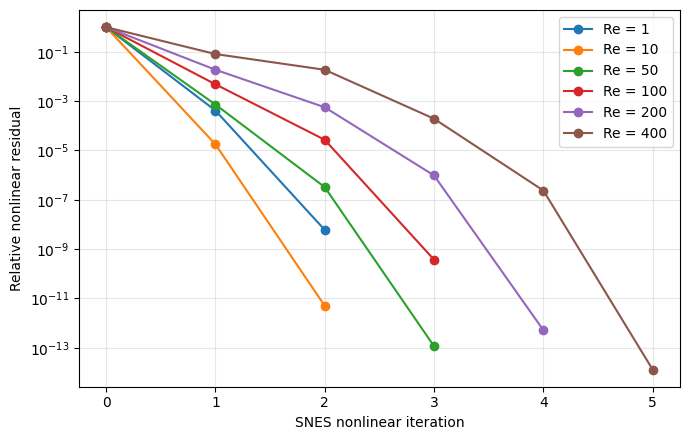

Final Re = 400
||div(u_h)||_L2 = 9.347917e-01


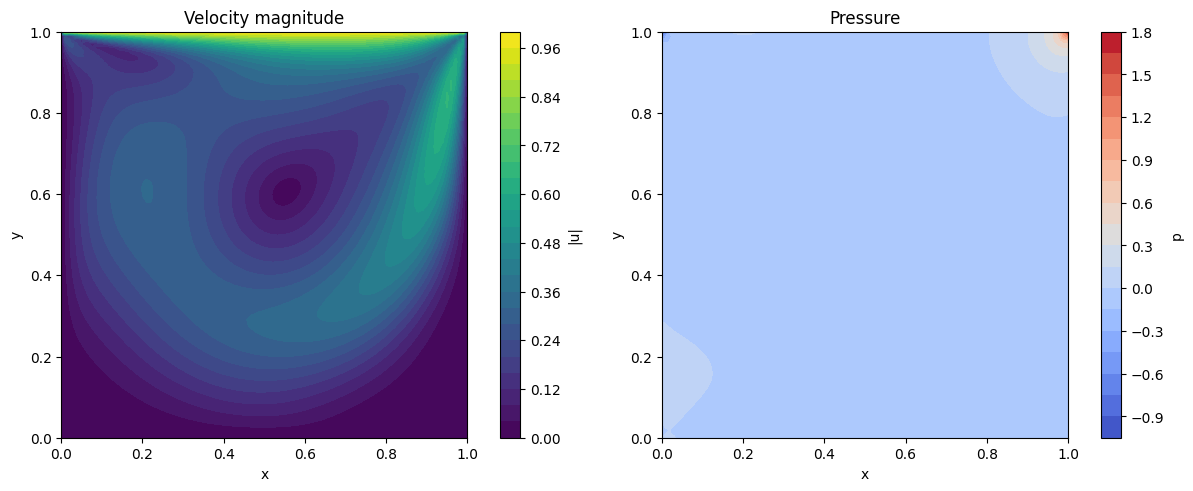

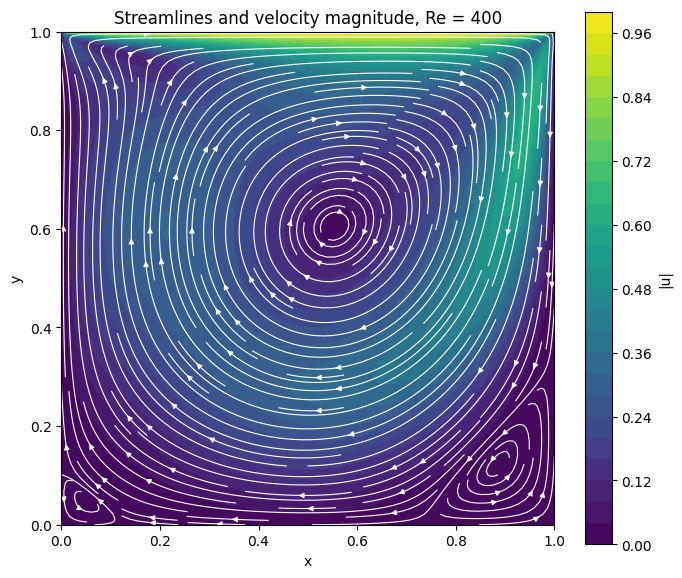

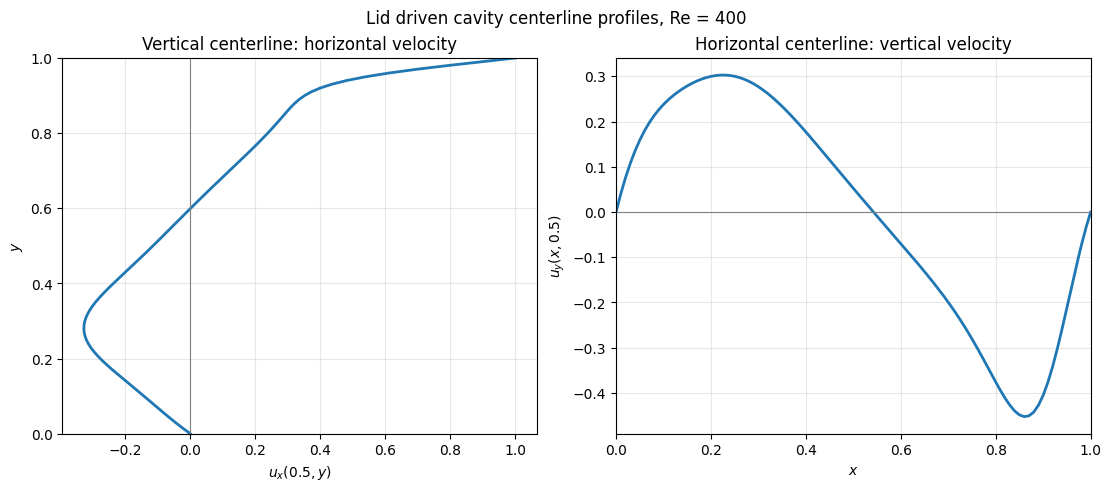

In [14]:
# Postprocessing: nonlinear residual, velocity/pressure fields,
# streamlines, and the two standard cavity centerline velocity profiles.

from dolfinx import geometry

if msh.comm.size != 1:
    raise RuntimeError("This plotting cell is intended for a single-process Colab run.")

# Split the converged mixed solution for field plots and evaluation.
u_h = solution.sub(0).collapse()
p_h = solution.sub(1).collapse()
u_h.x.scatter_forward()
p_h.x.scatter_forward()

# 1. Nonlinear residual history
fig, ax = plt.subplots(figsize=(7, 4.5))
for Re, values in histories.items():
    if values:
        values = np.asarray(values)
        base = values[0] if values[0] > 0 else 1.0
        ax.semilogy(
            np.arange(len(values)),
            np.maximum(values / base, 1.0e-16),
            "o-",
            label=f"Re = {Re:g}",
        )
ax.set_xlabel("SNES nonlinear iteration")
ax.set_ylabel("Relative nonlinear residual")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Assemble the squared divergence locally, then sum across MPI ranks.
div2_local = fem.assemble_scalar(
    fem.form(ufl.div(u)**2 * ufl.dx(domain=msh))
)
div_l2 = np.sqrt(msh.comm.allreduce(div2_local, op=MPI.SUM))
print(f"Final Re = {TARGET_RE:g}")
print(f"||div(u_h)||_L2 = {div_l2:.6e}")

# 2. Velocity magnitude and pressure at the P1 nodes
xy_u = u_h.function_space.tabulate_dof_coordinates()[:, :2]
uv_nodes = u_h.x.array.reshape((-1, 2))
xy_p = p_h.function_space.tabulate_dof_coordinates()[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)

speed_nodes = np.linalg.norm(uv_nodes, axis=1)
c0 = axes[0].tricontourf(
    xy_u[:, 0], xy_u[:, 1], speed_nodes,
    levels=25, cmap="viridis"
)
fig.colorbar(c0, ax=axes[0], label="|u|")
axes[0].set_title("Velocity magnitude")

c1 = axes[1].tricontourf(
    xy_p[:, 0], xy_p[:, 1], p_h.x.array,
    levels=25, cmap="coolwarm"
)
fig.colorbar(c1, ax=axes[1], label="p")
axes[1].set_title("Pressure")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.show()

# Evaluate the finite element velocity in its actual mesh cells.
# This avoids interpolating the centerline data using a different triangulation.
tree = geometry.bb_tree(msh, msh.topology.dim, padding=1.0e-10)

def evaluate_velocity(points_xy):
    """Find each point's mesh cell and evaluate the finite element velocity."""
    points_xy = np.asarray(points_xy, dtype=msh.geometry.x.dtype)
    points = np.zeros((len(points_xy), 3), dtype=msh.geometry.x.dtype)
    points[:, :2] = points_xy

    candidates = geometry.compute_collisions_points(tree, points)
    collisions = geometry.compute_colliding_cells(msh, candidates, points)

    cells = np.array(
        [
            collisions.links(i)[0] if len(collisions.links(i)) else -1
            for i in range(len(points))
        ],
        dtype=np.int32,
    )
    if np.any(cells < 0):
        raise RuntimeError(
            f"{np.count_nonzero(cells < 0)} evaluation points were not found in the mesh."
        )

    return np.asarray(u_h.eval(points, cells)).reshape((-1, 2))

# 3. Streamline field on a regular grid inside the cavity
# Keep sample points slightly inside the walls for robust cell lookup.
grid = np.linspace(1.0e-6, 1.0 - 1.0e-6, 151)
X, Y = np.meshgrid(grid, grid)
velocity_grid = evaluate_velocity(
    np.column_stack((X.ravel(), Y.ravel()))
).reshape((len(grid), len(grid), 2))

Ux = velocity_grid[:, :, 0]
Uy = velocity_grid[:, :, 1]
speed_grid = np.hypot(Ux, Uy)

fig, ax = plt.subplots(figsize=(7, 6))
background = ax.contourf(
    X, Y, speed_grid, levels=30, cmap="viridis"
)
ax.streamplot(
    grid, grid, Ux, Uy,
    color="white",
    density=2.0,
    linewidth=0.8,
    arrowsize=0.8,
)
fig.colorbar(background, ax=ax, label="|u|")
ax.set_title(f"Streamlines and velocity magnitude, Re = {TARGET_RE:g}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

# 4. Standard centerline profiles:
#    horizontal velocity u_x along x = 0.5;
#    vertical velocity u_y along y = 0.5.
y_sample = np.linspace(1.0e-6, 1.0 - 1.0e-6, 201)
x_sample = np.linspace(1.0e-6, 1.0 - 1.0e-6, 201)

vertical_points = np.column_stack(
    (np.full_like(y_sample, 0.5), y_sample)
)
horizontal_points = np.column_stack(
    (x_sample, np.full_like(x_sample, 0.5))
)

u_center = evaluate_velocity(vertical_points)[:, 0]
v_center = evaluate_velocity(horizontal_points)[:, 1]

# Add exact Dirichlet values at the wall endpoints of both profiles.
y_plot = np.r_[0.0, y_sample, 1.0]
u_plot = np.r_[0.0, u_center, 1.0]
x_plot = np.r_[0.0, x_sample, 1.0]
v_plot = np.r_[0.0, v_center, 0.0]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)

axes[0].plot(u_plot, y_plot, lw=2)
axes[0].axvline(0, color="0.5", lw=0.8)
axes[0].set_xlabel(r"$u_x(0.5,y)$")
axes[0].set_ylabel(r"$y$")
axes[0].set_title("Vertical centerline: horizontal velocity")
axes[0].set_ylim(0, 1)

axes[1].plot(x_plot, v_plot, lw=2)
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel(r"$u_y(x,0.5)$")
axes[1].set_title("Horizontal centerline: vertical velocity")
axes[1].set_xlim(0, 1)

for ax in axes:
    ax.grid(True, alpha=0.3)

fig.suptitle(f"Lid driven cavity centerline profiles, Re = {TARGET_RE:g}")
plt.show()


## Usage notes and references

- Run the notebook from top to bottom to obtain nonlinear iteration output and the final plots.
- To change the target Reynolds number, edit `TARGET_RE` and keep the final entry of `RE_STEPS` equal to it. For a gradual solve, use a strictly increasing sequence.
- For a mesh-convergence study, increase `N` and compare quantities such as the centerline velocity profiles. Stabilization does not replace mesh refinement.
- Streamlines and centerline profiles are plotted following the conventions described in the [COMSOL lid-driven cavity benchmark](https://www.comsol.com/blogs/how-to-solve-a-classic-cfd-benchmark-the-lid-driven-cavity-problem) and the [PKU lid-driven cavity resource](https://math.pku.edu.cn/teachers/tanghz/private/homepage/Lid-drivencavityflow.htm).
- The solver uses the FEniCSx 0.10/0.11 `dolfinx.fem.petsc.NonlinearProblem` API. See the [DOLFINx nonlinear solver documentation](https://docs.fenicsproject.org/dolfinx/v0.11.0/python/generated/dolfinx.fem.petsc.html) and its [mixed lid-driven cavity example](https://docs.fenicsproject.org/dolfinx/v0.11.0/python/demos/demo_stokes.html).
